# TP2 · Búsqueda de hiperparámetros por etapas

Notebook aparte para correr en Colab. Trae todo lo necesario (datos, funciones de entrenamiento y evaluación) y después la grilla.

**Antes de empezar:** *Runtime → Change runtime type → T4 GPU → Save*, y después *Runtime → Run all*. La celda de reproducibilidad tiene que decir `Dispositivo: cuda`.

**Etapa 1: optimizador y learning rate juntos.** Van juntos porque el buen lr depende del optimizador. Cada uno se prueba en su propio rango, con el resto fijo en la configuración del TP (capas ocultas 128–64, dropout 0,2, batch 100, 20 épocas, semilla 42):

| Optimizador | learning rates |
|---|---|
| SGD | 0,003 · 0,01 · 0,03 · 0,1 |
| Adam | 0,0003 · 0,001 · 0,003 |

Gana la combinación con mayor exactitud de validación en la última época, y pasa a ser la **base** de la etapa 2.

**Etapas 2, 3 y 4: capas ocultas → batch → dropout**, en ese orden. En cada etapa se cambia un solo hiperparámetro y, si el mejor valor le gana a la configuración actual por más de 0,3 puntos (un poco más que la variación entre semillas), se adopta para las etapas siguientes:

| Etapa | Valores | Por qué esos |
|---|---|---|
| capas ocultas | 64-32 · 128-64 · 256-128 · 512-256 · 256-128-64 | siempre al menos dos capas ocultas |
| batch | 50 · 100 · 200 | con **early stopping** (ver abajo) |
| dropout | 0 · 0,1 · 0,2 · 0,3 · 0,4 | sin pasar de 0,4–0,5 |

**Early stopping en la etapa del batch.** Cambiar el batch cambia cuántas actualizaciones de pesos hay por época (batch 50 = 1000 por época; batch 200 = 250), así que con 20 épocas fijas la comparación no es pareja: el batch grande «entrena menos». Por eso en esa etapa cada configuración entrena hasta 50 épocas y **corta cuando la pérdida de validación no mejora durante 5 épocas seguidas** (`PATIENCE`); se compara en su **mejor época**. Las otras etapas siguen con 20 épocas fijas, como el TP, y el modelo final también se entrena 20 épocas.

Las **épocas** no se corren aparte: se leen de las curvas (columna «mejor época» = la de menor pérdida de validación).

Son unos **17 entrenamientos** (los de la etapa del batch, más largos) (los repetidos se reutilizan). En GPU calculo unos 10–15 minutos.

Para cambiar los valores o el orden de las etapas, editá `STAGE1` o `STAGES` (el orden del diccionario es el orden de las etapas). `UMBRAL = 0` se queda siempre con el máximo. Cuantos más valores, más tiempo.

> **EN:** Staged hyperparameter search (in Spanish): optimizer + learning rate first, then hidden layers → batch size (with early stopping) → dropout, changing one hyperparameter at a time and keeping a change only if it beats the current configuration by more than 0.3 points of validation accuracy. Run on a Colab T4 GPU.

In [ ]:
# 1) Librerías
# ----------------------------------------------------------------------
import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [ ]:
# 1.2) Reproducibilidad y dispositivo
SEED = 42

def set_seed(seed):
    """Fija todas las fuentes de azar que usamos: random de Python, NumPy y PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [ ]:
# 2.1) Transformación: píxeles 0..255 -> [0,1] (ToTensor) -> [-1,1] (Normalize)
transform = transforms.Compose([
    transforms.ToTensor(),                  # (28,28) uint8 0..255  ->  (1,28,28) float 0..1
    transforms.Normalize((0.5,), (0.5,)),   # x_norm = (x - 0.5) / 0.5  ->  [-1, 1]
])

full_train = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# Precarga: aplicamos la transformación UNA vez y guardamos todo como tensores en memoria.
# El resultado es idéntico (la transformación no tiene azar) y el entrenamiento es ~10 veces más rápido,
# porque el DataLoader ya no convierte imagen por imagen en cada época.
from torch.utils.data import TensorDataset

def to_tensor_dataset(ds):
    xs, ys = zip(*DataLoader(ds, batch_size=10_000))
    return TensorDataset(torch.cat(xs), torch.cat(ys))

full_train = to_tensor_dataset(full_train)
test_set   = to_tensor_dataset(test_set)

# 2.2) Train / validation / test
generator = torch.Generator().manual_seed(SEED)       # el corte 50.000 / 10.000 queda fijo
train_set, valid_set = random_split(full_train, [50_000, 10_000], generator=generator)

print("train:", len(train_set), " validation:", len(valid_set), " test:", len(test_set))

train: 50000  validation: 10000  test: 10000


In [ ]:
# 3) DataLoaders
BATCH_SIZE = 100

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)
train_eval_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False)   # para medir train sin consumir el azar

In [ ]:
# 6) Función de pérdida y épocas
loss_fn = nn.CrossEntropyLoss()      # recibe logits (B,10) y etiquetas enteras (B,)
EPOCHS = 20

In [ ]:
# 8) Una época de entrenamiento
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()                                   # 1. modo entrenamiento (Dropout activo)
    for images, labels in data_loader:
        images = images.to(device)                  # 2. al dispositivo
        labels = labels.to(device)
        optimizer.zero_grad()                       # 3. borrar gradientes viejos
        logits = model(images)                      # 4. forward
        loss = loss_fn(logits, labels)              # 5. Cross-Entropy
        loss.backward()                             # 6. backpropagation (calcula gradientes)
        optimizer.step()                            # 7. actualiza los pesos

In [ ]:
# 9) Evaluación: pérdida y accuracy, sin tocar los pesos
def evaluate(model, data_loader, loss_fn, device):
    model.eval()                                    # Dropout apagado
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():                           # no se arma el grafo de gradientes
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)
            b = labels.size(0)
            total_loss += loss.item() * b           # loss es promedio del batch: lo pasamos a suma
            predictions = logits.argmax(dim=1)      # clase de mayor logit
            correct += (predictions == labels).sum().item()
            n += b
    return total_loss / n, correct / n

## Grilla

In [ ]:
# Herramientas de la grilla: una MLP con cualquier número de capas ocultas y una función que entrena una configuración
import time

def make_mlp(hidden, dropout_p):
    """784 -> hidden[0] -> ... -> hidden[-1] -> 10 (logits), con ReLU y Dropout después de cada capa oculta."""
    layers, n_in = [nn.Flatten()], 28 * 28
    for n_out in hidden:
        layers += [nn.Linear(n_in, n_out), nn.ReLU(), nn.Dropout(dropout_p)]
        n_in = n_out
    layers.append(nn.Linear(n_in, 10))
    return nn.Sequential(*layers)

def make_optimizer(name, params, lr):
    if name == "SGD":
        return torch.optim.SGD(params, lr=lr)
    if name == "Adam":
        return torch.optim.Adam(params, lr=lr)
    raise ValueError(name)

MAX_EPOCHS = 50    # tope de épocas cuando se usa early stopping
PATIENCE = 5       # early stopping: cortar si la pérdida de validación no mejora en 5 épocas seguidas

def run_config(cfg, epochs=EPOCHS, seed=SEED):
    """Entrena una configuración desde cero con la misma semilla y devuelve las curvas.
    Si cfg tiene "es" (early stopping), entrena hasta MAX_EPOCHS, corta cuando la pérdida de
    validación no mejora en cfg["es"] épocas, y las métricas que se comparan son las de la mejor época."""
    set_seed(seed)
    loader = DataLoader(train_set, batch_size=cfg["batch"], shuffle=True)
    model = make_mlp(cfg["hidden"], cfg["dropout"]).to(device)
    optimizer = make_optimizer(cfg["opt"], model.parameters(), cfg["lr"])
    patience = cfg.get("es")
    h = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}
    best_loss, waited = float("inf"), 0
    for epoch in range(1, (MAX_EPOCHS if patience else epochs) + 1):
        train_one_epoch(model, loader, loss_fn, optimizer, device)
        tl, ta = evaluate(model, train_eval_loader, loss_fn, device)
        vl, va = evaluate(model, valid_loader, loss_fn, device)
        h["train_loss"].append(tl); h["train_acc"].append(ta)
        h["valid_loss"].append(vl); h["valid_acc"].append(va)
        if patience:
            if vl < best_loss:
                best_loss, waited = vl, 0
                h["best_epoch"] = epoch
            else:
                waited += 1
                if waited >= patience:
                    break
    return h

def final(h, key):
    """Métrica con la que se compara: la de la mejor época si hubo early stopping, si no la de la última."""
    return h[key][h["best_epoch"] - 1] if "best_epoch" in h else h[key][-1]

def label(cfg):
    es = f", early stop ({cfg['es']})" if cfg.get("es") else ""
    return (f"{cfg['opt']} lr={cfg['lr']:g}, ocultas={'-'.join(map(str, cfg['hidden']))}, "
            f"dropout={cfg['dropout']}, batch={cfg['batch']}{es}")

def show(cfg, h):
    tl, vl, va = final(h, "train_loss"), final(h, "valid_loss"), final(h, "valid_acc")
    ep = (f"época elegida {h['best_epoch']:2d} (cortó en {len(h['valid_loss'])})" if "best_epoch" in h
          else f"mejor época {int(np.argmin(h['valid_loss'])) + 1:2d}")
    print(f"{label(cfg):<55} valid acc {100*va:5.1f} %  valid loss {vl:.3f}  brecha {vl - tl:.3f}  {ep}")

cache = {}                             # label -> curvas; así no se repite un entrenamiento
def run_cached(cfg):
    key = label(cfg)
    if key not in cache:
        cache[key] = run_config(cfg)
    return cache[key]


In [ ]:
# ETAPA 1: optimizador y learning rate juntos.
# Cada optimizador con su propio rango de lr (un factor ~3 entre valores), alrededor de su valor típico.
# El resto queda fijo en la configuración del TP: ocultas 128-64, dropout 0.2, batch 100, 20 épocas, semilla 42.
FIXED = {"hidden": (128, 64), "dropout": 0.2, "batch": 100}
STAGE1 = {
    "SGD":  [0.003, 0.01, 0.03, 0.1],
    "Adam": [0.0003, 0.001, 0.003],
}

t0 = time.time()
stage1 = {}
for opt, lrs in STAGE1.items():
    for lr in lrs:
        cfg = dict(FIXED, opt=opt, lr=lr)
        stage1[(opt, lr)] = run_cached(cfg)
        show(cfg, stage1[(opt, lr)])
print(f"[{time.time() - t0:.0f} s]")

# La mejor combinación según la exactitud de validación en la última época
best_opt, best_lr = max(stage1, key=lambda k: stage1[k]["valid_acc"][-1])
BASE = dict(FIXED, opt=best_opt, lr=best_lr)
print("\nElegida para la etapa 2:", label(BASE))


SGD lr=0.003, ocultas=128-64, dropout=0.2, batch=100    valid acc  82.7 %  valid loss 0.488  brecha 0.016  mejor época 20
SGD lr=0.01, ocultas=128-64, dropout=0.2, batch=100     valid acc  86.2 %  valid loss 0.381  brecha 0.026  mejor época 20
SGD lr=0.03, ocultas=128-64, dropout=0.2, batch=100     valid acc  88.4 %  valid loss 0.325  brecha 0.051  mejor época 19
SGD lr=0.1, ocultas=128-64, dropout=0.2, batch=100      valid acc  89.0 %  valid loss 0.307  brecha 0.083  mejor época 20
Adam lr=0.0003, ocultas=128-64, dropout=0.2, batch=100  valid acc  89.1 %  valid loss 0.309  brecha 0.077  mejor época 20
Adam lr=0.001, ocultas=128-64, dropout=0.2, batch=100   valid acc  88.9 %  valid loss 0.318  brecha 0.106  mejor época 15
Adam lr=0.003, ocultas=128-64, dropout=0.2, batch=100   valid acc  88.2 %  valid loss 0.343  brecha 0.098  mejor época 15
[269 s]

Elegida para la etapa 2: Adam lr=0.0003, ocultas=128-64, dropout=0.2, batch=100


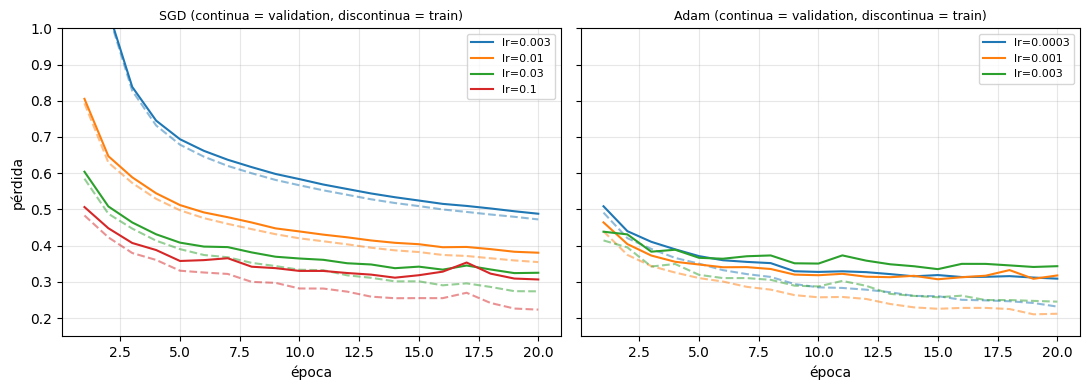

In [ ]:
# Curvas de la etapa 1: pérdida de validation (continua) y train (discontinua) para cada optimizador y lr
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (opt, lrs) in zip(axes, STAGE1.items()):
    for lr in lrs:
        h = stage1[(opt, lr)]
        line, = ax.plot(range(1, EPOCHS + 1), h["valid_loss"], "-", label=f"lr={lr:g}")
        ax.plot(range(1, EPOCHS + 1), h["train_loss"], "--", color=line.get_color(), alpha=.5)
    ax.set_title(f"{opt} (continua = validation, discontinua = train)", fontsize=9)
    ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("pérdida"); axes[0].set_ylim(0.15, 1.0)
plt.tight_layout(); plt.show()


Cómo leer estas curvas (clase del 12/11): si la pérdida baja **muy lento**, el lr es chico; si baja de golpe y queda **ruidosa** o sube, es grande. Si train y validation se **separan**, hay sobreajuste.

### Etapas 2 a 4: capas ocultas, batch y dropout

In [ ]:
# ETAPAS 2, 3 y 4: capas ocultas -> batch -> dropout, en ese orden.
# En cada etapa se cambia UN hiperparámetro respecto de la configuración actual (BASE).
# Si el mejor valor le gana a BASE por más de UMBRAL, pasa a ser la nueva BASE para la etapa siguiente.
# La etapa del batch se corre con EARLY STOPPING: cambiar el batch cambia cuántas actualizaciones hay por
# época (batch 50 = 1000 por época, batch 200 = 250), así que con 20 épocas fijas no se compara parejo.
# Con early stopping cada batch entrena lo que necesita y se compara en su mejor época.
UMBRAL = 0.003     # 0,3 puntos de exactitud: un poco más que la variación entre semillas (~0,2).
                   # Con UMBRAL = 0 se queda siempre con el máximo, aunque la diferencia sea ruido.
STAGES = {
    "hidden":  [(64, 32), (128, 64), (256, 128), (512, 256), (256, 128, 64)],  # siempre al menos dos capas ocultas
    "batch":   [50, 100, 200],                                             # con early stopping
    "dropout": [0.0, 0.1, 0.2, 0.3, 0.4],                                     # nunca más de 0,4-0,5 (clase 12/11)
}

EARLY_STOP = {"batch"}          # etapas que se corren con early stopping
t0 = time.time()
stage_results = {}                 # hp -> {valor: curvas}
stage_bases = {}                   # hp -> BASE con la que se corrió esa etapa
for hp, values in STAGES.items():
    stage_bases[hp] = dict(BASE)
    print(f"--- Etapa: {hp}  (base: {label(BASE)})")
    extra = {"es": PATIENCE} if hp in EARLY_STOP else {}
    stage_results[hp] = {}
    for v in values:
        cfg = dict(BASE, **{hp: v}, **extra)
        stage_results[hp][v] = run_cached(cfg)
        show(cfg, stage_results[hp][v])
    ref = stage_results[hp][BASE[hp]] if BASE[hp] in values else cache[label(BASE)]   # misma regla de épocas
    base_acc = final(ref, "valid_acc")
    v_best = max(values, key=lambda v: final(stage_results[hp][v], "valid_acc"))
    gain = final(stage_results[hp][v_best], "valid_acc") - base_acc
    if v_best != BASE[hp] and gain > UMBRAL:
        BASE = dict(BASE, **{hp: v_best})
        print(f"=> cambia {hp} a {v_best} (+{100*gain:.1f} puntos)\n")
    else:
        print(f"=> se mantiene {hp} = {BASE[hp]} (la mejora máxima fue {100*gain:+.1f} puntos)\n")
print("Configuración final:", label(BASE), f"[{time.time() - t0:.0f} s]")


--- Etapa: hidden  (base: Adam lr=0.0003, ocultas=128-64, dropout=0.2, batch=100)
Adam lr=0.0003, ocultas=64-32, dropout=0.2, batch=100   valid acc  88.1 %  valid loss 0.334  brecha 0.050  mejor época 20
Adam lr=0.0003, ocultas=128-64, dropout=0.2, batch=100  valid acc  89.1 %  valid loss 0.309  brecha 0.077  mejor época 20
Adam lr=0.0003, ocultas=256-128, dropout=0.2, batch=100 valid acc  89.1 %  valid loss 0.305  brecha 0.107  mejor época 19
Adam lr=0.0003, ocultas=512-256, dropout=0.2, batch=100 valid acc  89.6 %  valid loss 0.298  brecha 0.139  mejor época 17
Adam lr=0.0003, ocultas=256-128-64, dropout=0.2, batch=100 valid acc  89.3 %  valid loss 0.297  brecha 0.095  mejor época 20
=> cambia hidden a (512, 256) (+0.5 puntos)

--- Etapa: batch  (base: Adam lr=0.0003, ocultas=512-256, dropout=0.2, batch=100)
Adam lr=0.0003, ocultas=512-256, dropout=0.2, batch=50, early stop (5) valid acc  89.9 %  valid loss 0.290  brecha 0.130  época elegida 17 (cortó en 22)
Adam lr=0.0003, ocultas=5

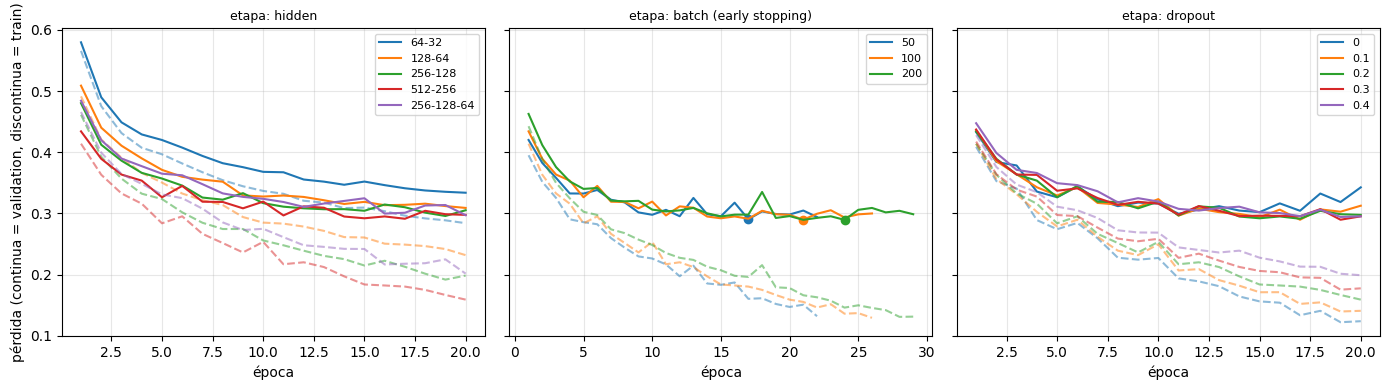

In [ ]:
# Curvas de cada etapa: un panel por hiperparámetro
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (hp, values) in zip(axes, STAGES.items()):
    for v in values:
        h = stage_results[hp][v]
        name = "-".join(map(str, v)) if hp == "hidden" else f"{v:g}"
        ep = range(1, len(h["valid_loss"]) + 1)          # con early stopping cada curva tiene su largo
        line, = ax.plot(ep, h["valid_loss"], "-", label=name)
        ax.plot(ep, h["train_loss"], "--", color=line.get_color(), alpha=.5)
        if "best_epoch" in h:                              # punto = época elegida por early stopping
            ax.plot(h["best_epoch"], h["valid_loss"][h["best_epoch"] - 1], "o", color=line.get_color())
    ax.set_title(f"etapa: {hp}" + (" (early stopping)" if hp in EARLY_STOP else ""), fontsize=9); ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("pérdida (continua = validation, discontinua = train)")
plt.tight_layout(); plt.show()


## Tabla de resultados

Un bloque por etapa. El asterisco marca el valor con el que se siguió. **Δ** es la diferencia de exactitud de validación con la configuración de partida de esa etapa; con otra semilla la exactitud se mueve unos **0,2 puntos**, así que una diferencia de ese tamaño no es una mejora real. **Brecha** = loss valid − loss train: si crece, hay más sobreajuste.

In [ ]:
# Tabla para el informe: un bloque por etapa. * = valor con el que siguió la etapa siguiente.
# "Δ" es la diferencia de exactitud de validación con la base de ESA etapa.
# En la etapa del batch (ES = early stopping) las métricas son las de la época elegida, no las de la última.
def row(name, value, h, ref_acc, mark=""):
    tl, vl, va = final(h, "train_loss"), final(h, "valid_loss"), final(h, "valid_acc")
    ep = (f"{h['best_epoch']} (ES, cortó {len(h['valid_loss'])})" if "best_epoch" in h
          else f"{int(np.argmin(h['valid_loss'])) + 1}")
    print(f"{name:<8} {value + mark:<13} {tl:>10.3f} {vl:>10.3f} {vl - tl:>7.3f} {100*va:>8.1f}% "
          f"{100*(va - ref_acc):>+6.1f}  {ep:>11}")
print(f"{'etapa':<8} {'valor':<13} {'loss train':>10} {'loss valid':>10} {'brecha':>7} {'acc valid':>9} {'Δ':>6} {'mejor época':>11}")
best1 = max(stage1, key=lambda k: stage1[k]["valid_acc"][-1])
ref = stage1[best1]["valid_acc"][-1]
for (opt, lr), h in stage1.items():
    row(opt, f"lr={lr:g}", h, ref, "*" if (opt, lr) == best1 else "")
print()
hps = list(STAGES)
for i, hp in enumerate(hps):
    chosen = (stage_bases[hps[i + 1]] if i + 1 < len(hps) else BASE)[hp]
    b = stage_bases[hp]
    ref = final(stage_results[hp][b[hp]] if b[hp] in STAGES[hp] else cache[label(b)], "valid_acc")
    for v in STAGES[hp]:
        name = "-".join(map(str, v)) if hp == "hidden" else f"{v:g}"
        row(hp, name, stage_results[hp][v], ref, "*" if v == chosen else "")
    print()
print("Final:", label(BASE))


etapa    valor         loss train loss valid  brecha acc valid      Δ mejor época
SGD      lr=0.003           0.472      0.488   0.016     82.7%   -6.5           20
SGD      lr=0.01            0.355      0.381   0.026     86.2%   -2.9           20
SGD      lr=0.03            0.274      0.325   0.051     88.4%   -0.7           19
SGD      lr=0.1             0.223      0.307   0.083     89.0%   -0.1           20
Adam     lr=0.0003*         0.232      0.309   0.077     89.1%   +0.0           20
Adam     lr=0.001           0.212      0.318   0.106     88.9%   -0.2           15
Adam     lr=0.003           0.245      0.343   0.098     88.2%   -0.9           15

hidden   64-32              0.284      0.334   0.050     88.1%   -1.0           20
hidden   128-64             0.232      0.309   0.077     89.1%   +0.0           20
hidden   256-128            0.198      0.305   0.107     89.1%   +0.0           19
hidden   512-256*           0.159      0.298   0.139     89.6%   +0.5           17
hidd

**Ojo con una cosa:** al encadenar etapas, cada una depende de lo que se eligió antes (por ejemplo, el mejor dropout puede ser otro con una red más grande). Es una búsqueda razonable y fácil de explicar, pero no garantiza encontrar la mejor combinación posible. Vale la pena decirlo en el informe.

## Test del modelo final (una sola vez)

Recién ahora, con la configuración ya elegida por validation, se entrena ese modelo (20 épocas, misma semilla: da el mismo modelo que en la grilla) y se evalúa **una vez** en test. La matriz de confusión del informe sale de este `model`.

In [ ]:
set_seed(SEED)
loader = DataLoader(train_set, batch_size=BASE["batch"], shuffle=True)
model = make_mlp(BASE["hidden"], BASE["dropout"]).to(device)
optimizer = make_optimizer(BASE["opt"], model.parameters(), BASE["lr"])
for epoch in range(EPOCHS):
    train_one_epoch(model, loader, loss_fn, optimizer, device)
test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
print(label(BASE), f"-> test loss {test_loss:.3f}, test acc {100*test_acc:.1f} %")

Adam lr=0.0003, ocultas=512-256, dropout=0.2, batch=100 -> test loss 0.325, test acc 88.9 %
